# Week 4 · Your Week 3 work, reviewed

I read your Week 3 log (22 hours, Oct 26–31) and every cell you added. This notebook answers what you asked for. **B** draws the two SVM ideas you wanted pictures for. **C** draws fancy indexing and `keepdims`. **D** practises recursion in small steps, since `build_tree` was the hard one. AdaBoost and gradient boosting get a whole notebook of their own next (`01`), in small pieces, as you asked.

**How to use this notebook**
- Run cells one at a time with **Shift + Enter**.
- Before running an example, **guess what it prints**. The real result is written after `# →` in the comments, so you can check yourself.
- **Your turn** cells are for you. Open **Show one answer** only after a real attempt.
- If things get weird, click **Restart** at the top and run from the top again.

**Run this cell first.** It loads NumPy, the picture helpers (`figures.py` in this folder) and the exercise checker.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from figures import *
import checks; checks.load(globals(), "00")      # defines check(n)

## M. The map: what's in this notebook and why

🖼 **Picture.** This week. Weeks 2–3 had labels to learn from; this week has none: you look for structure in `X` alone. Then the checkpoint.

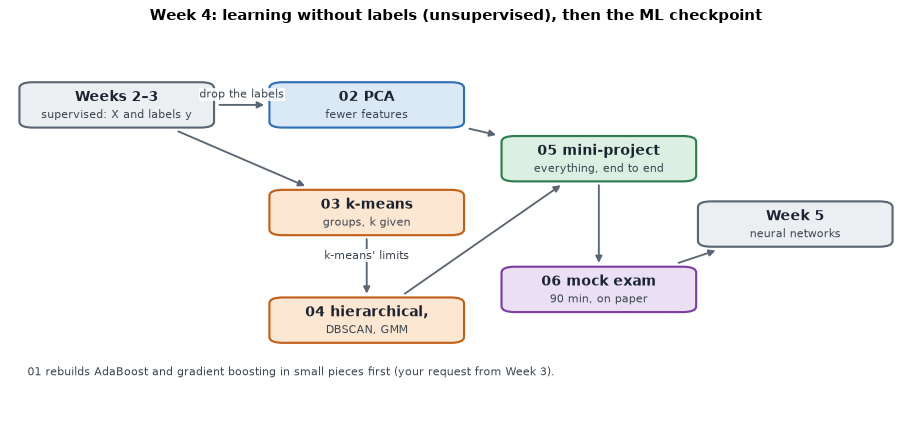

In [2]:
fig_week_map()

| Section | What | Why it's here |
|---|---|---|
| 0 | recap | your Week 3 misses: the loss functions, fancy indexing, `keepdims` |
| A | your code and notes, reviewed | what was right, what to change, and answers to the questions in your comments |
| B | SVM in two pictures | you asked for a picture of the distance-as-projection idea and found the dual → kernel step hard |
| C | fancy indexing and `keepdims`, drawn | 02's exercises 15 and 16 were unclear |
| D | recursion in small steps | `build_tree` and `predict_tree` (04, exercises 6–7) were the hardest; trees come back in every exam |

## 0. Recap first · 10 min, closed book

**Quick check:** Write the loss that linear regression, ridge and lasso each minimize.

<details><summary>Answer</summary>

Linear: $\frac{1}{n}\sum_i (y_i - w^\top x_i - b)^2$. Ridge: the same $+\ \lambda \lVert w \rVert_2^2 = \lambda \sum_j w_j^2$. Lasso: the same $+\ \lambda \lVert w \rVert_1 = \lambda \sum_j \lvert w_j \rvert$. The bias $b$ is never penalized. (You missed this in Week 3's recap.) [Week 2 · 04 §6–7 ↗](../week2/04_ml_intro_linear_regression.ipynb)

</details>

**Quick check:** Which of ridge and lasso can set a weight to **exactly** 0, and why?

<details><summary>Answer</summary>

Lasso. Its penalty $\lvert w_j \rvert$ has a corner at 0, so the optimum often sits right at the corner; ridge's $w_j^2$ is smooth there, so it only shrinks. [Week 2 · 04 §7 ↗](../week2/04_ml_intro_linear_regression.ipynb)

</details>

**Quick check:** `np.eye(3)[[2, 0]]` is ...?

<details><summary>Answer</summary>

`[[0, 0, 1], [1, 0, 0]]`: rows 2 and 0 of the identity matrix. Section C draws it. [Week 3 · 02, exercise 15 ↗](../week3/02_knn_and_numpy_workout.ipynb)

</details>

**Quick check:** `Z` has shape `(4, 3)`. Shapes of `Z.sum(axis=1)` and `Z.sum(axis=1, keepdims=True)`?

<details><summary>Answer</summary>

`(4,)` and `(4, 1)`. Only the second can be used in `Z / ...` to divide each row by its own sum. Section C draws it.

</details>

**Quick check:** In AdaBoost, what happens to the weights of the points a stump got wrong?

<details><summary>Answer</summary>

They're multiplied by $e^{\alpha}$ (up) while the right ones are multiplied by $e^{-\alpha}$ (down); then everything is divided by the sum. Afterwards the mistakes hold exactly half the total weight. [Week 3 · 06 §5 ↗](../week3/06_ensembles.ipynb)

</details>

## A. Your Week 3 code and notes, reviewed

Most important first. Each point opens with what you wrote, linked back to it.

**A1. kNN without the square root: a good shortcut, and why it's allowed**

> ↩ **Recap** · [Week 3 · 02 exercise 4 (kNN for one query) ↗](../week3/02_knn_and_numpy_workout.ipynb)
>
> You wrote `dist = ((X_train - q)**2).sum(axis=1)` with no `np.sqrt`, then `np.argsort(dist)[:k]`. It passed.

It passes because the square root never changes the **order** of non-negative numbers: if $a < b$, then $\sqrt a < \sqrt b$. `argsort` only cares about the order, so squared distances give the same neighbours, and you skip one operation for every training point. scikit-learn does the same internally. You'd need the real distance only when you report it or weight neighbours by it.

In [3]:
d2 = np.array([7.25, 6.25, 2.25, 3.25])          # squared distances
print(np.argsort(d2), np.argsort(np.sqrt(d2)))    # → [2 3 1 0] [2 3 1 0]   same order

[2 3 1 0] [2 3 1 0]


**A2. Your axis recipe for kNN is exactly right**

> ↩ **Recap** · [Week 3 · 02 §7, your note "kNN: which axis to sum, which to sort" ↗](../week3/02_knn_and_numpy_workout.ipynb)
>
> You named the axes of `diff` (0 = test point, 1 = training point, 2 = feature) and wrote the rule: for `sum`/`mean`/`norm`, ask which axis should **disappear**; for `argsort`/`argmax`, ask which axis you're **choosing among**.

That rule is the whole skill. It comes back this week: in k-means (`03`), the distances from $n$ points to $k$ centroids form an `(n, k)` table. You `argmin` along axis 1 (choose among centroids) to assign each point. Your `rbf_kernel` (05, exercise 6) used the same `(m, n, d)` trick once you saw it; your double-loop version was also correct, just slower.

**A3. Labels that aren't numbers: your question about `majority_vote`**

> ↩ **Recap** · [Week 3 · 06 exercise 2 (majority vote) ↗](../week3/06_ensembles.ipynb)
>
> You asked: *"How does this count change for when the labels are not integers? What do the labels look like for the test cases?"*

In the tests, `P` had shape `(B, m)` filled with whole numbers 0, 1, 2, e.g. `[[0, 1, 1], [1, 1, 0], [0, 1, 0]]` (3 models × 3 test points), and the answer was `[0, 1, 0]`. I should have shown that; from now on every exercise has an **Example** with real inputs and the expected output. For text labels, `np.bincount` fails: it needs whole numbers ≥ 0. Turn the text into codes first:

In [4]:
labels = np.array(["cat", "dog", "cat"])
names, codes = np.unique(labels, return_inverse=True)   # names = the distinct labels, codes = each label's position in names
print(names, codes)                    # → ['cat' 'dog'] [0 1 0]
print(names[np.bincount(codes).argmax()])   # → cat

['cat' 'dog'] [0 1 0]
cat


**A4. `w -= ...` changes the array in place**

> ↩ **Recap** · [Week 3 · 05 exercise 4 (train a linear SVM) ↗](../week3/05_svm.ipynb)
>
> You wrote `w -= lr*step_w`, and noted (in Korean) to unpack the gradient tuple once instead of calling `hinge_grad` twice. That note is right.

`w -= x` and `w = w - x` give the same numbers, but `-=` writes into the **existing** array, while `w = w - x` makes a new one. Inside your function `w` was made by `np.zeros`, so it was safe. It bites when the array came from outside: the caller's variable changes too. That's the copies-and-views lesson from [Week 1 · NumPy §11 ↗](../week1/02_numpy_lesson.ipynb), and PyTorch (Week 5) has the same rule with `w.sub_(...)`.

In [5]:
w_start = np.zeros(2)
def train(w):
    w -= 0.1 * np.array([1.0, 2.0])     # in place: changes the array that was passed in
    return w
w_end = train(w_start)
print(w_start)                          # → [-0.1 -0.2]   the caller's array changed too!

[-0.1 -0.2]


**A5. Your `best_threshold` and `best_split`: correct, with one tidy-up**

> ↩ **Recap** · [Week 3 · 04 exercises 4–5 ↗](../week3/04_decision_trees.ipynb)
>
> You collected `(threshold, gain)` pairs in a list and returned `max(results, key=lambda t: t[1])`.

Correct, and `max` with `key` is neat: on ties it returns the **first** maximum, which is the smallest threshold, as required. Using `x < m` and `x > m` instead of `<=` is fine too, because a midpoint never equals a data value. One tidy-up: you call `np.unique(x)` again on every loop pass. Compute it once into a variable; on big data that's the difference between fast and slow.

**A6. Your notes**

| Where | Your note | Verdict |
|---|---|---|
| [04 §2 ↗](../week3/04_decision_trees.ipynb) | Gini as the chance that two picks differ, with 7 A / 3 B → 0.42 | Correct, and a cleaner example than mine. |
| [03 §5–6 ↗](../week3/03_pandas_methods.ipynb) | `dropna(subset=...)`; `groupby` returns a plan, `transform` broadcasts back | Correct. `.groups` and `.get_group` are good finds. |
| [06, top ↗](../week3/06_ensembles.ipynb) | The big-picture flowchart: variance branch (bagging → random forest) vs bias branch (AdaBoost → gradient boosting) | Exactly right. It's why every notebook now opens with a map like it (section M). |
| [02 ex. 17 ↗](../week3/02_knn_and_numpy_workout.ipynb) | "didnt know there was a thing like `X[y == c]`" | A True/False mask on axis 0 keeps whole rows. You'll use it all week: the points of cluster $c$ are `X[labels == c]`. |

**What you did well**

- You found a shortcut (no square root) and it was mathematically sound.
- You wrote your own axis rule, and it's the right general rule.
- When an exercise was too hard, you studied the solution and wrote down what you didn't know, which is the right way to use a solution.
- You recapped the whole week on your own and told me what would make the notebooks easier to review (the map at the top).

## B. SVM in two pictures

**B1. The distance to a line is a projection**

> ↩ **Recap** · [Week 3 · 05 §2 ↗](../week3/05_svm.ipynb)
>
> The signed distance from $x$ to the line $w^\top x + b = 0$ is $\frac{w^\top x + b}{\lVert w \rVert}$. The derivation took any point $x_0$ on the line and projected $x - x_0$ onto the direction of $w$. You asked for a picture of that step.

🖼 **Picture.** The line $x_1 + x_2 = 4.5$, i.e. $w = (1, 1)$, $b = -4.5$. Orange: the arrow from a point on the line, $x_0 = (3, 1.5)$, to $x = (1, 1)$. Thick blue: its **shadow** on the direction of $w$. That shadow's length is the distance, the same length as the dashed perpendicular from $x$ to the line.

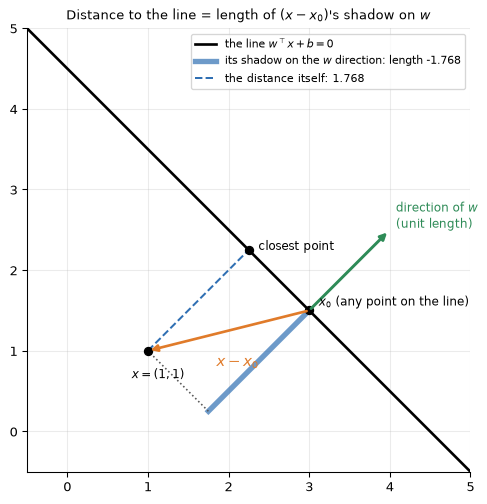

In [6]:
fig_svm_distance()

- $x - x_0 = (1, 1) - (3, 1.5) = (-2, -0.5)$.
- The unit vector along $w$ is $u = \frac{(1, 1)}{\sqrt 2} = (0.707, 0.707)$.
- The shadow's signed length is $u^\top (x - x_0) = 0.707 \times (-2) + 0.707 \times (-0.5) = -1.768$. The minus sign means $x$ is on the side $w$ points **away** from.
- Same answer from the formula: $\frac{w^\top x + b}{\lVert w \rVert} = \frac{1 + 1 - 4.5}{1.414} = -1.768$. Any $x_0$ on the line gives the same shadow, because moving $x_0$ along the line moves it at right angles to $u$, which adds 0.

**B2. From the dual to kernels, in three steps**

> ↩ **Recap** · [Week 3 · 05 §7 (the dual problem) ↗](../week3/05_svm.ipynb)
>
> From the Lagrangian: $w = \sum_i \alpha_i y_i x_i$, where only the support vectors have $\alpha_i > 0$. For the six points, $\alpha_i y_i = -\frac{2}{9}, -\frac{2}{9}, +\frac{4}{9}$ for $(2, 1)$, $(1, 2)$, $(3, 3)$, and $b = -3$.

**Step 1: $w$ is made of support vectors.** Walk the three scaled support vectors tip to tail and you land on $w$:

🖼 **Picture.** $w = -\frac{2}{9}(2, 1) - \frac{2}{9}(1, 2) + \frac{4}{9}(3, 3) = (0.667, 0.667)$. No other training point is needed.

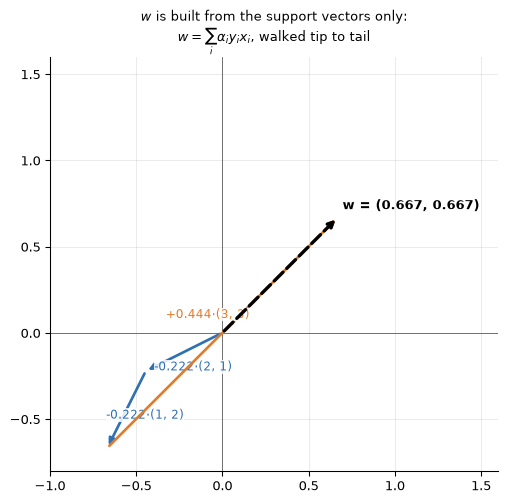

In [7]:
fig_dual_sum()

**Step 2: so a prediction needs only dot products with the support vectors.** Put $w = \sum_i \alpha_i y_i x_i$ into the score of a new point $x$:

$$
w^\top x + b = \Big(\sum_i \alpha_i y_i x_i\Big)^\top x + b = \sum_i \alpha_i y_i \underbrace{(x_i^\top x)}_{\text{a dot product}} + b
$$

| Support vector $x_i$ | $\alpha_i y_i$ | $x_i^\top x$ for $x = (2, 3)$ | product |
|---|---|---|---|
| (2, 1) | −2/9 | 2·2 + 1·3 = 7 | −14/9 |
| (1, 2) | −2/9 | 1·2 + 2·3 = 8 | −16/9 |
| (3, 3) | +4/9 | 3·2 + 3·3 = 15 | +60/9 |
| sum, + b |  |  | $\frac{30}{9} - 3 = 0.333$ |

Check: directly, $w^\top x + b = 0.667 \times 2 + 0.667 \times 3 - 3 = 0.333$ ✓. **The two ways give the same score, but the second never uses $w$**: only dot products between the new point and the support vectors.

**Step 3: replace each dot product with a kernel.** A kernel $k(x_i, x)$ is a dot product in a bigger feature space ([Week 3 · 05 §8 ↗](../week3/05_svm.ipynb)). Swap it in and the score becomes $f(x) = \sum_i \alpha_i y_i\, k(x_i, x) + b$. With the RBF kernel, each support vector contributes a **bump** centred on itself:

🖼 **Picture.** A 1-D example (orange in the middle, blue outside, which no single threshold separates). Thin lines: one bump per support vector, pointing up for orange and down for blue. Thick: their sum plus $b$. It's positive exactly over the orange region, so the boundary is curved, yet the SVM only ever computed dot products (kernels).

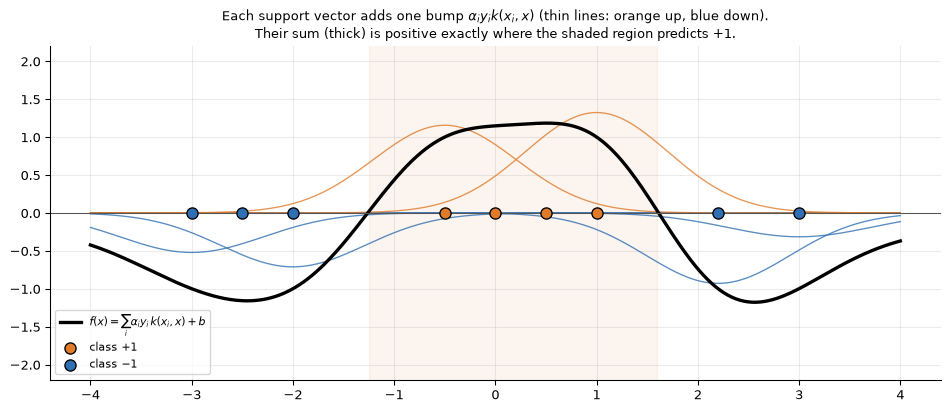

In [8]:
fig_dual_bumps()

**In one sentence:** the dual says the answer is a weighted sum over support vectors, a weighted sum only needs dot products, and a kernel is a dot product, so swapping in a kernel gives a curved boundary for free.

## C. Fancy indexing and `keepdims`, drawn

**C1. `np.eye(k)[y]`: picking rows of the identity matrix**

> ↩ **Recap** · [Week 3 · 02 exercise 15 (one-hot) ↗](../week3/02_knn_and_numpy_workout.ipynb)
>
> You wrote `return np.eye(k)[y]` and it passed, but your log said you didn't understand what was going on.

🖼 **Picture.** `np.eye(3)` has a 1 on the diagonal: row $c$ is the one-hot vector for class $c$. Indexing with `y = [2, 0, 1]` picks rows 2, 0, 1, in that order: one row per sample.

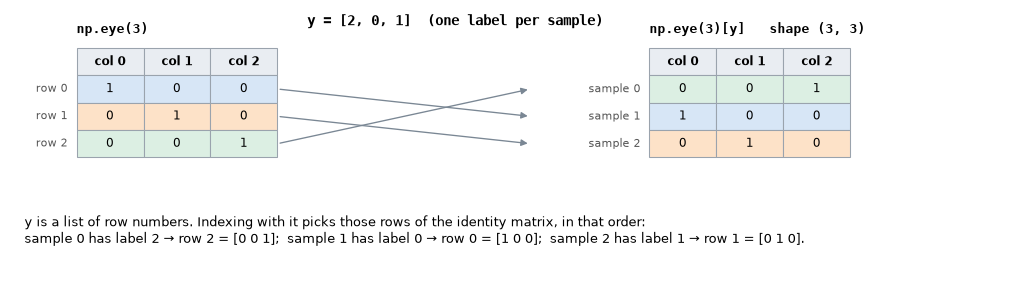

In [9]:
fig_eye_index()

It's the same fancy indexing as `y_train[idx]` in kNN ([Week 3 · 02 §4 ↗](../week3/02_knn_and_numpy_workout.ipynb)), applied to the **rows** of a 2-D array: a list of row numbers gives back those rows, stacked.

**C2. `keepdims=True` keeps a column you can broadcast with**

> ↩ **Recap** · [Week 3 · 02 exercise 16 (softmax per row) ↗](../week3/02_knn_and_numpy_workout.ipynb)
>
> You wrote `Z - np.max(Z, axis=1, keepdims=True)` and found `keepdims` hard.

🖼 **Picture.** Subtracting each row's maximum. `keepdims=True` gives shape `(2, 1)` instead of `(2,)`, and only `(2, 1)` lines up with `(2, 3)`.

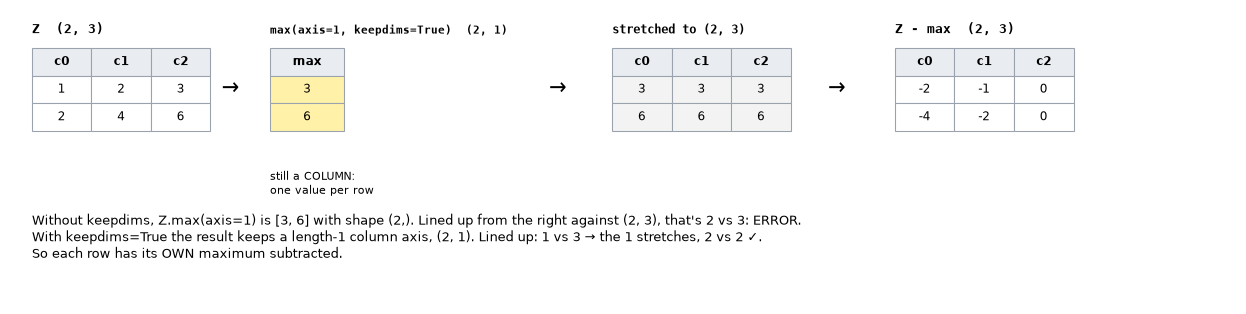

In [10]:
fig_keepdims()

In [22]:
Z = np.array([[1, 2, 3], [2, 4, 6]])
print(Z.max(axis=1).shape, Z.max(axis=1, keepdims=True).shape)   # → (2,) (2, 1)
print(Z - Z.max(axis=1, keepdims=True))
# → [[-2 -1  0]
#    [-4 -2  0]]
try:
    Z - Z.max(axis=1)
except ValueError as e:
    print("ValueError:", str(e)[:52])
# → ValueError: operands could not be broadcast together with shapes

(2,) (2, 1)
[[-2 -1  0]
 [-4 -2  0]]
ValueError: operands could not be broadcast together with shapes


✏️ **Exercise 1 · Normalize the rows.** Divide every row of `Z` (shape `(n, d)`, positive numbers) by its own sum, so each row sums to 1. **Shape `(n, d)`.** One line with `keepdims=True`.

**Example**: what goes in, and what should come out:
```python
Z = np.array([[1.0, 2.0, 3.0],
              [2.0, 4.0, 6.0]])     # (2, 3), float
normalize_rows(Z)
# → [[0.167 0.333 0.5  ]
#    [0.167 0.333 0.5  ]]     each row sums to 1
```

In [23]:
def normalize_rows(Z):
    sum = Z.sum(axis = 1, keepdims = True)
    return Z / sum

In [24]:
check(1)

Exercise 1: PASS


✏️ **Exercise 2 · Majority label for any labels.** `labels` is a 1-D array of **text** labels. Return the most common one (ties → the alphabetically first). Use `np.unique(..., return_inverse=True)` as in A3.

**Example**: what goes in, and what should come out:
```python
majority_label(np.array(["dog", "cat", "dog"]))   # → 'dog'
majority_label(np.array(["owl", "bee"]))          # → 'bee'   (a tie: 'bee' comes first alphabetically)
```

In [48]:
names, codes = np.unique(np.array(["dog", "cat", "dog"]), return_inverse = True)
print(codes)
print(names)
print(np.bincount(codes).argmax())

[1 0 1]
['cat' 'dog']
1


In [44]:
def majority_label(labels):
    names , codes = np.unique(labels, return_inverse = True)
    return names[np.bincount(codes).argmax()]

In [45]:
check(2)

Exercise 2: PASS


## D. Recursion in small steps

> ↩ **Recap** · [Week 3 · 04 exercises 6–7 (build and predict) ↗](../week3/04_decision_trees.ipynb)
>
> A tree is a dictionary: a leaf is `{"leaf": 1}`; a node is `{"feature": j, "threshold": t, "left": <tree>, "right": <tree>}`. `build_tree` calls itself on the left rows and on the right rows.

**A recursive function has two parts:** a **base case** that answers directly (a leaf), and a **recursive case** that answers by calling itself on smaller pieces and combining the results. To write one, don't trace the whole thing in your head. Ask two questions: *what's the answer for a leaf?* and *if I already had the answers for the left and right subtrees, how would I combine them?*

| Function | Base case (a leaf) | Combine the two subtrees |
|---|---|---|
| count the leaves | 1 | left count + right count |
| depth | 0 | 1 + the bigger of the two depths |
| predict one point | the leaf's label | only go down ONE side: left if `x[feature] <= threshold` |
| build_tree (Week 3) | majority label, when the node is pure or depth is used up | a node whose children are the two recursive builds |

The tree from Week 3 · 04 §1, as a dictionary. It has 3 leaves and depth 2:

In [60]:
tree = {"feature": 1, "threshold": 0.5,
        "left":  {"leaf": 0},
        "right": {"feature": 0, "threshold": 72.0,
                  "left": {"leaf": 0}, "right": {"leaf": 1}}}

print(tree["left"])
print(tree["left"]["leaf"])

{'leaf': 0}
0


✏️ **Exercise 3 · Count the leaves.** Return how many leaves the tree has. Base case: a leaf counts 1. Otherwise: the leaves on the left plus the leaves on the right.

**Example**: what goes in, and what should come out:
```python
count_leaves({"leaf": 1})   # → 1
count_leaves(tree)          # → 3   (the tree above)
```

In [56]:
def count_leaves(tree):
    if "leaf" in tree:
        return 1
    return count_leaves(tree["left"]) + count_leaves(tree["right"])

# I had to look up the solution for this one. Nice recursion. Does this return the total number of leaves in a tree no matter how deep the tree is?
# Very clever

In [57]:
check(3)

Exercise 3: PASS


✏️ **Exercise 4 · Depth.** Return the number of questions on the longest path from the root to a leaf. A single leaf has depth 0.

**Example**: what goes in, and what should come out:
```python
tree_depth({"leaf": 0})   # → 0
tree_depth(tree)          # → 2   root → right → a leaf
```

In [64]:
def tree_depth(tree):
    if "leaf" in tree:
        return 0
    return 1 + max(tree_depth(tree["left"]), tree_depth(tree["right"]))

In [59]:
check(4)

Exercise 4: PASS


In [63]:
for n in range(1, 5):
    check(n)

Exercise 1: PASS
Exercise 2: PASS
Exercise 3: PASS
Exercise 4: PASS


---
Solutions: `solutions/00_solutions.py`. Next: `01_boosting_step_by_step.ipynb`.